# 03 — Deep Learning Models (Autoencoder + Entity-Embedding MLP) & Full Benchmark (Parts A & C)

### Why Deep Learning for Real-Time Financial Fraud Streams?
1. **Unsupervised Deep Autoencoder (`15 → 32 → 16 → 6 → 16 → 32 → 15`)**: Trained *exclusively on legitimate transactions* to compress normal user behavior into a 6-dimensional latent manifold. Novel zero-day fraud patterns violate learned balance-flow conservation and produce high reconstruction MSE.
2. **Supervised Entity-Embedding MLP**: Maps categorical context (`hour` of day and `transaction type`) into dense learnable metric spaces (`nn.Embedding`) concatenated with continuous features and the Autoencoder's latent representation—flagging subtle multi-dimensional anomalies in **sub-millisecond per-transaction latency**.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
bench = json.loads((ROOT / 'models' / 'benchmark_summary.json').read_text())
df_all = pd.DataFrame(bench['benchmark_table'])[
    ['model', 'family', 'accuracy', 'pr_auc', 'f1', 'precision', 'recall', 'tp', 'fp', 'fn', 'tn', 'latency_ms']
]
df_all.style.format({
    'accuracy': '{:.4f}', 'pr_auc': '{:.4f}', 'f1': '{:.4f}',
    'precision': '{:.4f}', 'recall': '{:.4f}', 'latency_ms': '{:.4f} ms'
})

,model,family,accuracy,pr_auc,f1,precision,recall,tp,fp,fn,tn,latency_ms
0,Naive Majority Baseline (All Legit),Baseline,0.9890,0.0110,0.0000,0.0000,0.0000,0,0,179,16160,0.0010 ms
1,Static Rule Engine (isFlaggedFraud),Rule-Based,0.9890,0.0110,0.0000,0.0000,0.0000,0,0,179,16160,0.0050 ms
2,Logistic Regression,Classical ML,0.9977,0.9289,0.8812,1.0000,0.7877,141,0,38,16160,0.0002 ms
3,Isolation Forest,Unsupervised ML,0.9898,0.6878,0.5917,0.5261,0.6760,121,109,58,16051,0.0338 ms
4,XGBoost + SMOTE,Ensemble ML,0.9978,0.9398,0.8882,1.0000,0.7989,143,0,36,16160,0.0037 ms
5,Deep Autoencoder (Unsupervised),Deep Learning (Unsupervised),0.9968,0.7830,0.8301,1.0000,0.7095,127,0,52,16160,0.0009 ms
6,Entity-Embedding MLP (Deep Learning),Deep Learning (Supervised),0.9978,0.9437,0.8953,0.9333,0.8603,154,11,25,16149,0.0015 ms


## Precision–Recall Curves, Confusion Matrices & Autoencoder Latent Anomaly Separation

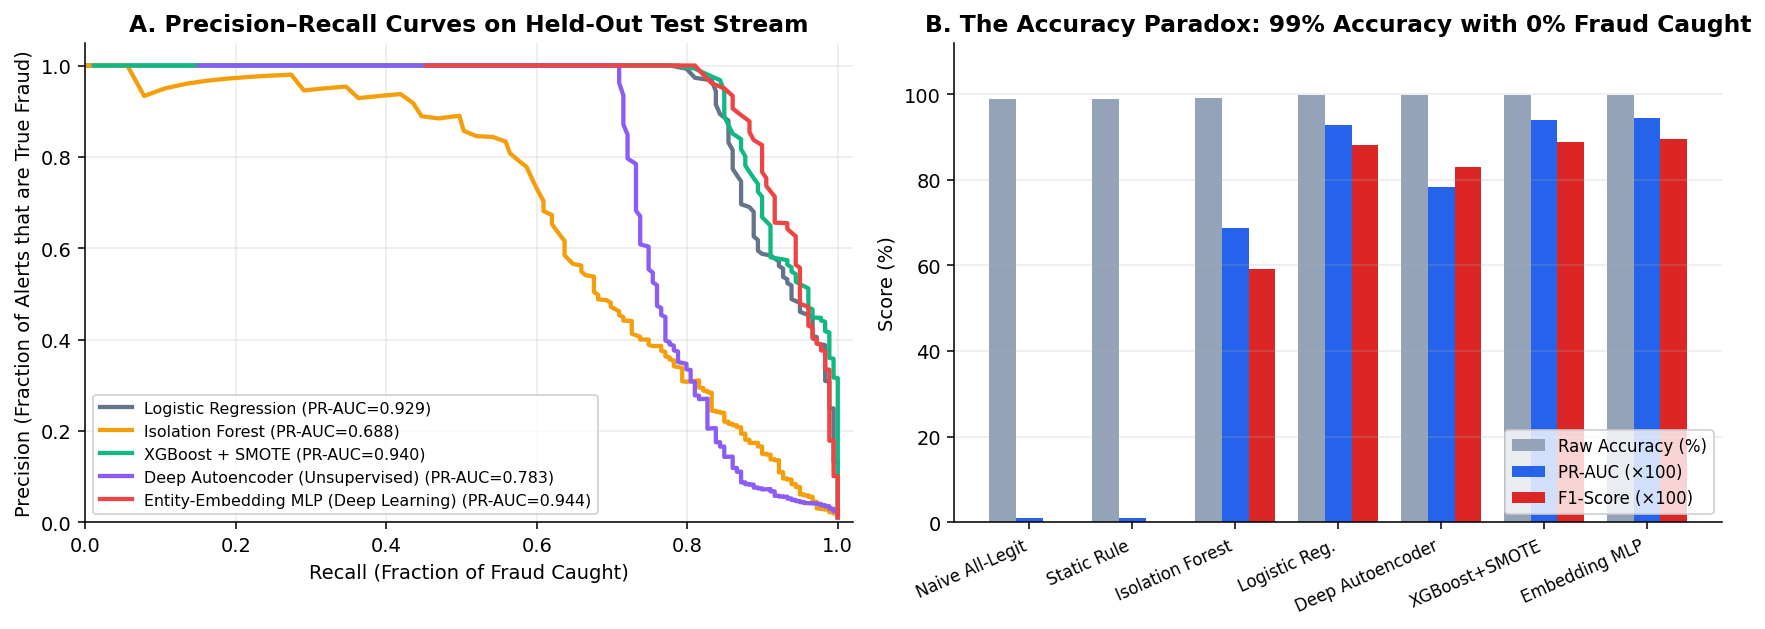

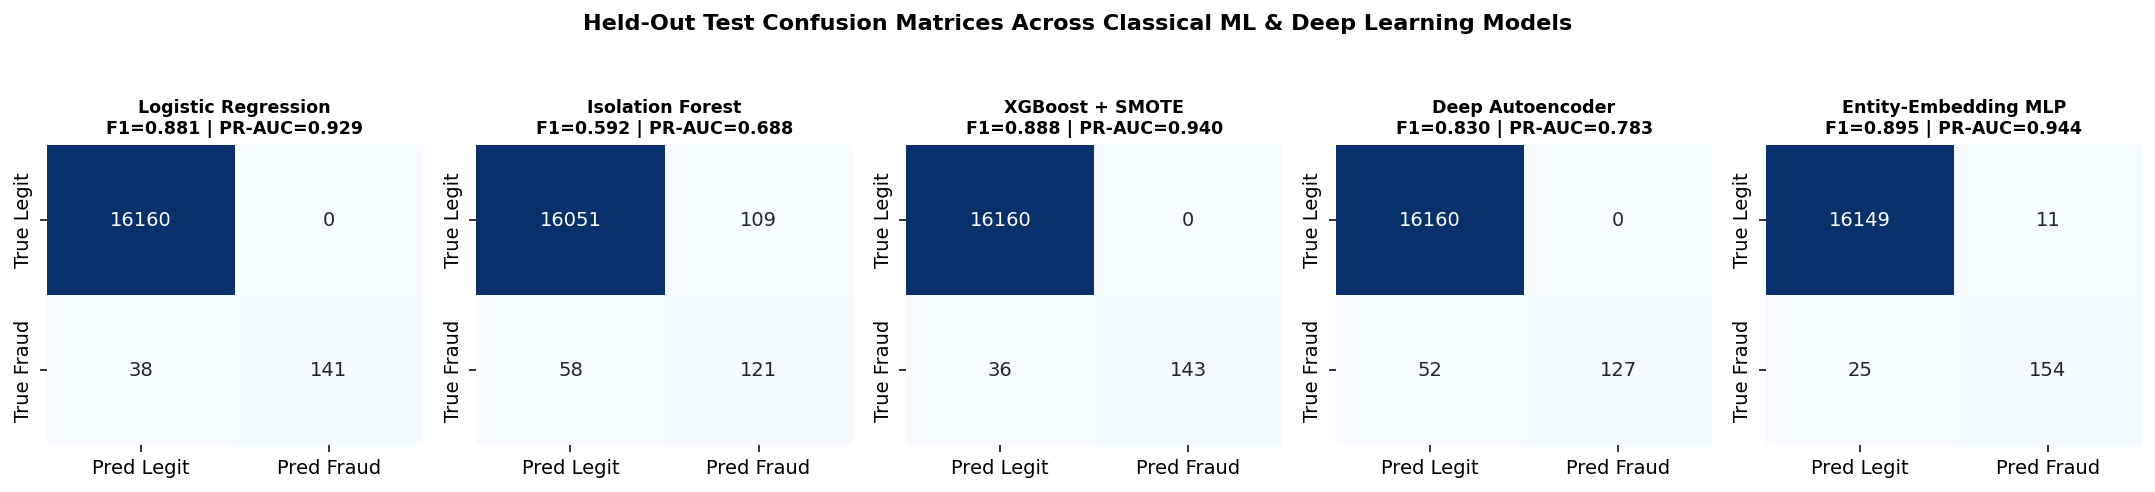

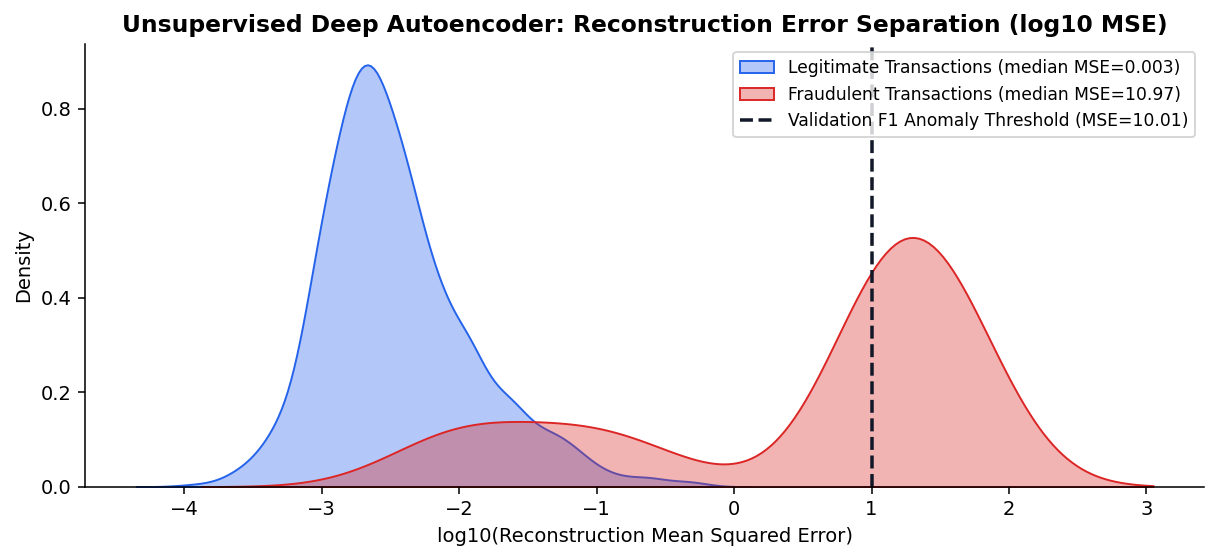

In [2]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'fig4_pr_curves_and_accuracy_paradox.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'fig5_confusion_matrices.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'fig6_autoencoder_reconstruction_error.png')))

## Ablation Comparison: Classical ML vs. Deep Learning Without Ledger-Error Features
When the explicit accounting identity columns (`errorBalanceOrig`, `errorBalanceDest`) are withheld, the models must rely on subtle multi-dimensional ratios, nocturnal timing embeddings, and latent interactions:

In [3]:
pd.DataFrame(bench['ablation_table'])[['model', 'pr_auc', 'f1', 'precision', 'recall']]

,model,pr_auc,f1,precision,recall
0,XGBoost + SMOTE (No Balance-Error Features),0.929167,0.886228,0.954839,0.826816
1,Entity-Embedding MLP (No Balance-Error Features),0.927444,0.881988,0.993007,0.793296
